## **Aplicação**: Determinação da profundidade de um fluido em um tanque esférico.

**Contexto**: Um tanque esférico de raio $R = 1$ metro contém um volume $V = 1$ m³ de combustível. Desejamos encontrar a profundidade $h$ que o combustível atinge.



Definição das Variáveis: $R = 1$ metro: Raio do tanque esférico.

$V = 1$ m³: Volume de combustível desejado dentro do tanque.

$h \in [0, 1]$: A profundidade do combustível (nossa incógnita).

$h = 0$: Tanque vazio.

$h = 1$: Tanque na metade (pois o raio é 1).

Como o volume total é $\approx 4.18$ m³, $1$ m³ estará abaixo da metade.


O volume de uma calota esférica é dado por $V = \frac{\pi h^2 (3R - h)}{3}$.


Substituindo $R=1$ e $V=1$, temos:$$1 = \frac{\pi h^2 (3 - h)}{3} \implies 3 = 3\pi h^2 - \pi h^3$$Portanto, nossa função para encontrar a raiz é:$$f(h) = \pi h^3 - 3\pi h^2 + 3$$

Enquanto a derivada da função é:
$$f'(h) = 3\pi h^2 - 6\pi h$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Função para truncamento (4 casas decimais)
def truncar(valor):
    if np.isnan(valor) or np.isinf(valor):
        return valor
    return np.trunc(valor * 10000) / 10000

# Função para arredondamento de exibição (3 casas decimais)
def arredondar(valor):
    return np.round(valor, 3)

# Definição da função f(h)
def f(h):
    res = np.pi * (h**3) - 3 * np.pi * (h**2) + 3
    return truncar(res)

# Derivada para o método de Newton
def df(h):
    res = 3 * np.pi * (h**2) - 6 * np.pi * h
    return truncar(res)

tol = 0.01

# Definindo o eixo h para a plotagem base
h_plot = np.linspace(0, 2.0, 400)
y_plot = np.array([f(val) for val in h_plot])

## Aplicação dos métodos

Para todos os métodos, utilizaremos a tolerância $\epsilon = 0.01$ (ou $10^{-2}$).

**Primeiro método: Método da bissecção**

- Intervalo Inicial: $[0, 1]$

- Critério de Parada: $|b - a| < \epsilon$

In [ ]:
#MÉTODO DA BISSECÇÃO

#Método que "separa" a raiz dividindo o intervalo ao meio sucessivamente.
print("=" * 65)
print(" MÉTODO DA BISSECÇÃO")
print("=" * 65)
print(f"{'k':<3} | {'a':<7} | {'b':<7} | {'x_k':<7} | {'f(x_k)':<8} | {'Erro |b-a|':<10}")
print("-" * 65)

a, b = 0.0, 1.0
k = 0

while (b - a) > tol:
    k += 1
    x_k = truncar((a + b) / 2)
    fx_k = f(x_k)
    erro = b - a

    print(f"{k:<3} | {a:<7.3f} | {b:<7.3f} | {x_k:<7.3f} | {fx_k:<8.3f} | {erro:<10.3f}")

    if f(a) * fx_k < 0:
        b = x_k
    else:
        a = x_k

raiz_biss = x_k
print(f"\n-> Raiz aproximada (Bissecção): {raiz_biss:.3f} m\n")

 MÉTODO DA BISSECÇÃO
k   | a       | b       | x_k     | f(x_k)   | Erro |b-a|
-----------------------------------------------------------------
1   | 0.000   | 1.000   | 0.500   | 1.036    | 1.000     
2   | 0.500   | 1.000   | 0.750   | -0.976   | 0.500     
3   | 0.500   | 0.750   | 0.625   | 0.085    | 0.250     
4   | 0.625   | 0.750   | 0.688   | -0.434   | 0.125     
5   | 0.625   | 0.688   | 0.656   | -0.171   | 0.062     
6   | 0.625   | 0.656   | 0.641   | -0.042   | 0.031     
7   | 0.625   | 0.641   | 0.633   | 0.022    | 0.016     

-> Raiz aproximada (Bissecção): 0.633 m



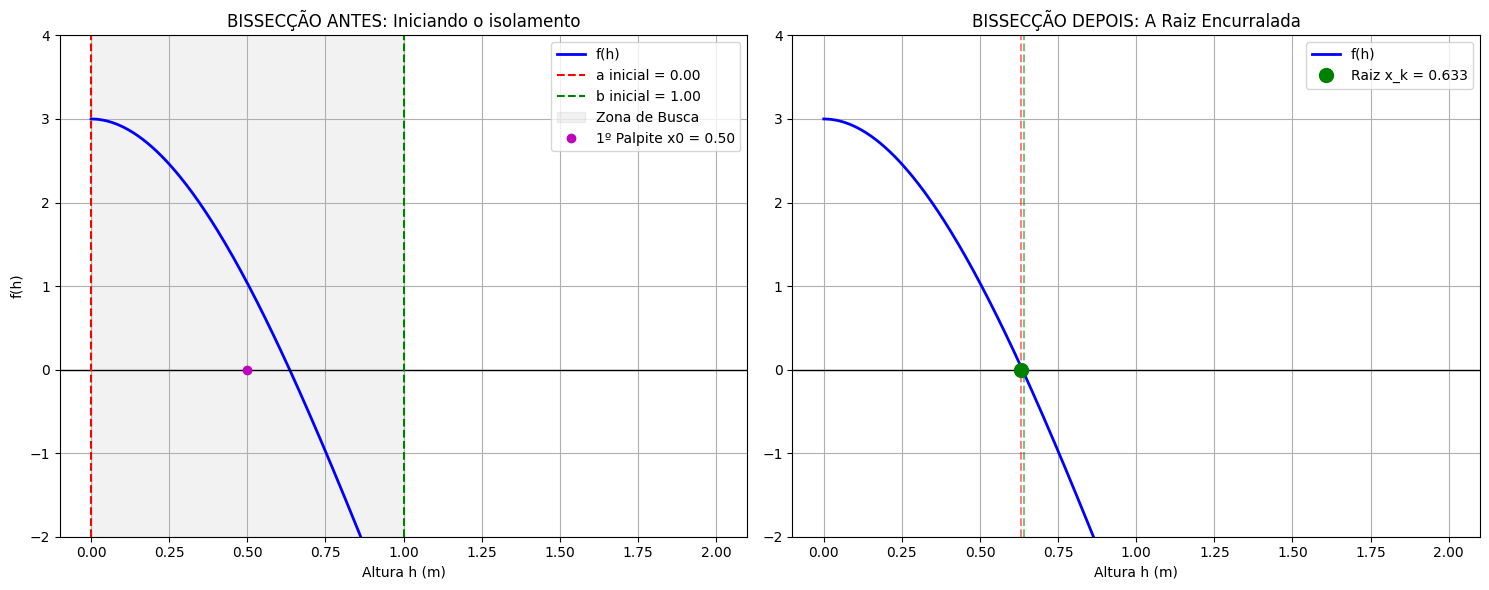

In [ ]:
def plot_bisseccao_antes_depois(a_inicial, b_inicial, a_final, b_final, raiz):
    plt.figure(figsize=(15, 6))

    # --- GRÁFICO 1: ANTES (O Cerco Inicial) ---
    plt.subplot(1, 2, 1)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Intervalo Inicial [a0, b0]
    plt.axvline(a_inicial, color="red", linestyle="--", label=f"a inicial = {a_inicial:.2f}")
    plt.axvline(b_inicial, color="green", linestyle="--", label=f"b inicial = {b_inicial:.2f}")

    # Área de Busca Inicial (Sombreada)
    plt.fill_between([a_inicial, b_inicial], -2, 4, color='gray', alpha=0.1, label="Zona de Busca")

    # Primeiro palpite (o meio exato)
    x0 = (a_inicial + b_inicial) / 2
    plt.plot(x0, 0, 'mo', label=f"1º Palpite x0 = {x0:.2f}")

    plt.title("BISSECÇÃO ANTES: Iniciando o isolamento")
    plt.xlabel("Altura h (m)"); plt.ylabel("f(h)")
    plt.ylim(-2, 4); plt.grid(True); plt.legend()

    # --- GRÁFICO 2: DEPOIS (O Cerco Final) ---
    plt.subplot(1, 2, 2)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Intervalo Final (quase invisível de tão perto)
    plt.axvline(a_final, color="red", linestyle="--", alpha=0.5)
    plt.axvline(b_final, color="green", linestyle="--", alpha=0.5)

    # Raiz encontrada
    plt.plot(raiz, 0, 'go', markersize=10, label=f"Raiz x_k = {raiz:.3f}")

    plt.title("BISSECÇÃO DEPOIS: A Raiz Encurralada")
    plt.xlabel("Altura h (m)"); plt.ylim(-2, 4); plt.grid(True); plt.legend()

    plt.tight_layout()
    plt.show()

# Exemplo de chamada (ajuste 'a' e 'b' para seus valores iniciais)
plot_bisseccao_antes_depois(0.0, 1.0, a, b, raiz_biss)

**Segundo método: Método da falsa posição**

- Critério de Parada: $|f(x_k)| < \epsilon$

In [ ]:
# MÉTODO DA FALSA POSIÇÃO

# Similiar à bissecção, mas utiliza uma média ponderada baseada nos valores f(a) e f(b)
# para encontrar a nova aproximação

# --- ALGORITMO ---
print("=" * 65)
print(" MÉTODO DA FALSA POSIÇÃO")
print("=" * 65)
print(f"{'k':<3} | {'a':<7} | {'b':<7} | {'x_k':<7} | {'f(x_k)':<8} | {'Erro |f(x_k)|':<12}")
print("-" * 65)

a, b = 0.0, 1.0
k = 0

while True:
    k += 1
    numerador = a * f(b) - b * f(a)
    denominador = f(b) - f(a)

    if denominador == 0:
        break

    x_k = truncar(numerador / denominador)
    fx_k = f(x_k)
    erro = abs(fx_k)

    print(f"{k:<3} | {a:<7.3f} | {b:<7.3f} | {x_k:<7.3f} | {fx_k:<8.3f} | {erro:<12.3f}")

    if erro <= tol:
        break

    if f(a) * fx_k < 0:
        b = x_k
    else:
        a = x_k

raiz_falsa = x_k
print(f"\n-> Raiz aproximada (Falsa Posição): {raiz_falsa:.3f} m\n")

 MÉTODO DA FALSA POSIÇÃO
k   | a       | b       | x_k     | f(x_k)   | Erro |f(x_k)|
-----------------------------------------------------------------
1   | 0.000   | 1.000   | 0.477   | 1.194    | 1.194       
2   | 0.477   | 1.000   | 0.617   | 0.152    | 0.152       
3   | 0.617   | 1.000   | 0.634   | 0.015    | 0.015       
4   | 0.634   | 1.000   | 0.635   | 0.002    | 0.002       

-> Raiz aproximada (Falsa Posição): 0.635 m



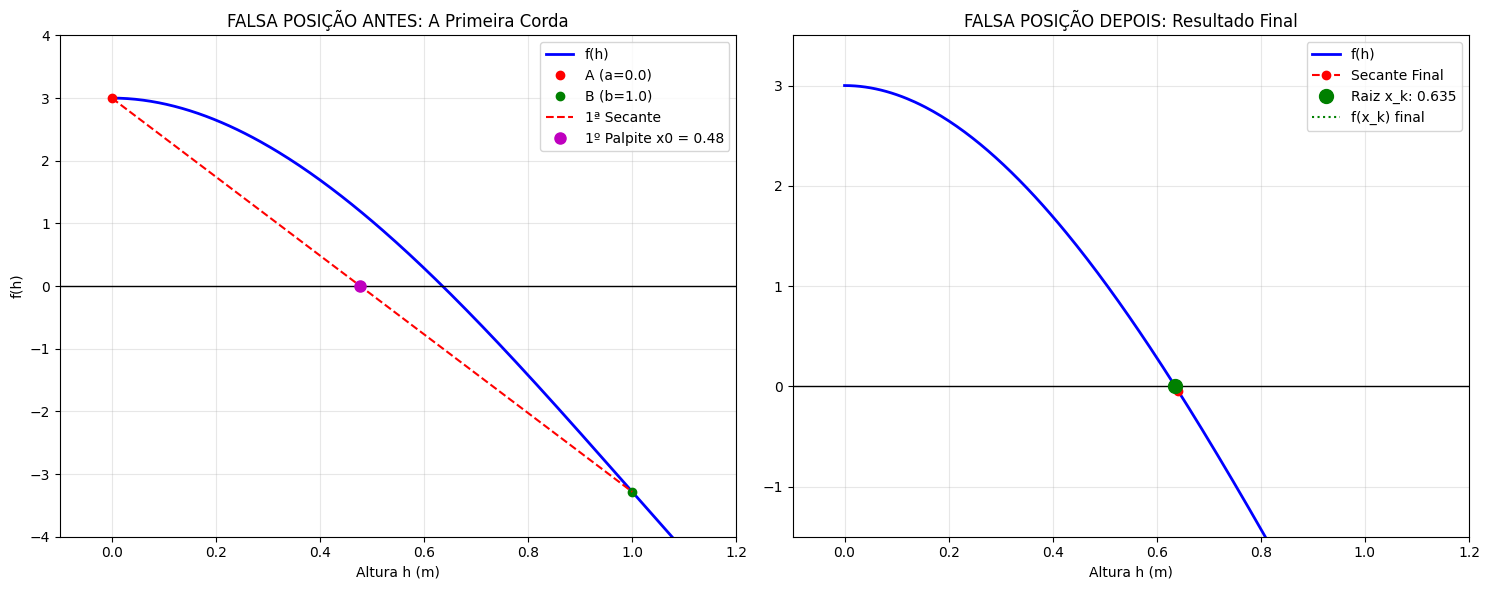

In [ ]:
def plot_falsa_posicao_antes_depois(a_ini, b_ini, a_fin, b_fin, raiz):
    plt.figure(figsize=(15, 6))

    # --- GRÁFICO 1: ANTES
    plt.subplot(1, 2, 1)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Pontos iniciais na curva
    plt.plot(a_ini, f(a_ini), 'ro', label=f'A (a={a_ini:.1f})')
    plt.plot(b_ini, f(b_ini), 'go', label=f'B (b={b_ini:.1f})')

    # 1ª Reta Secante (Corda inicial)
    plt.plot([a_ini, b_ini], [f(a_ini), f(b_ini)], color='red', linestyle='--', label='1ª Secante')

    # Primeiro palpite (x_0) onde a corda cruza o eixo
    x0 = (a_ini * f(b_ini) - b_ini * f(a_ini)) / (f(b_ini) - f(a_ini))
    plt.plot(x0, 0, 'mo', markersize=8, label=f"1º Palpite x0 = {x0:.2f}")

    plt.title("FALSA POSIÇÃO ANTES: A Primeira Corda")
    plt.xlabel("Altura h (m)"); plt.ylabel("f(h)")
    plt.xlim(-0.1, 1.2); plt.ylim(-4, 4); plt.grid(True, alpha=0.3); plt.legend()

    # --- GRÁFICO 2: DEPOIS (Convergência Final) ---
    plt.subplot(1, 2, 2)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Reta Secante Final (entre os últimos a e b encontrados)
    plt.plot([a_fin, b_fin], [f(a_fin), f(b_fin)], color='red', linestyle='--', marker='o', label='Secante Final')

    # Raiz aproximada final
    plt.plot(raiz, 0, 'go', markersize=10, label=f'Raiz x_k: {raiz:.3f}')

    # Projeção do erro f(x_k)
    plt.vlines(raiz, 0, f(raiz), colors='green', linestyles='dotted', label='f(x_k) final')

    plt.title("FALSA POSIÇÃO DEPOIS: Resultado Final")
    plt.xlabel("Altura h (m)"); plt.xlim(-0.1, 1.2); plt.ylim(-1.5, 3.5); plt.grid(True, alpha=0.3); plt.legend()

    plt.tight_layout()
    plt.show()

# Chamada (substitua pelos seus valores iniciais e finais)
plot_falsa_posicao_antes_depois(0.0, 1.0, a, b, raiz_falsa)

**Terceiro método: Método de newton-raphson**

- Ponto Inicial: $x_0 = 0.5$

- Critério de Parada: $|f(x_k)| < \epsilon$

In [ ]:
#MÉTODO DE NEWTON-RAPHSON

#Utiliza a reta tangente à função em um ponto inicial x0 para acelerar a convergência.
#também utilizando uma derivada.
print("=" * 65)
print(" MÉTODO DE NEWTON-RAPHSON")
print("=" * 65)
print(f"{'k':<3} | {'x_k':<7} | {'f(x_k)':<8} | {'f`(x_k)':<8} | {'x_k+1':<7} | {'Erro |f(x_k)|':<12}")
print("-" * 65)

x_k = 1.0
k = 0

while True:
    k += 1
    fx_k = f(x_k)
    dfx_k = df(x_k)
    erro = abs(fx_k)

    if dfx_k == 0:
        print("Erro: Derivada nula. O método falhou.")
        break

    x_k_next = truncar(x_k - fx_k / dfx_k)

    print(f"{k:<3} | {x_k:<7.3f} | {fx_k:<8.3f} | {dfx_k:<8.3f} | {x_k_next:<7.3f} | {erro:<12.3f}")

    if erro <= tol:
        break

    x_k = x_k_next

raiz_newton = x_k
print(f"\n-> Raiz aproximada (Newton-Raphson): {raiz_newton:.3f} m\n")

 MÉTODO DE NEWTON-RAPHSON
k   | x_k     | f(x_k)   | f`(x_k)  | x_k+1   | Erro |f(x_k)|
-----------------------------------------------------------------
1   | 1.000   | -3.283   | -9.425   | 0.652   | 3.283       
2   | 0.652   | -0.132   | -8.281   | 0.636   | 0.132       
3   | 0.636   | -0.001   | -8.173   | 0.635   | 0.001       

-> Raiz aproximada (Newton-Raphson): 0.636 m



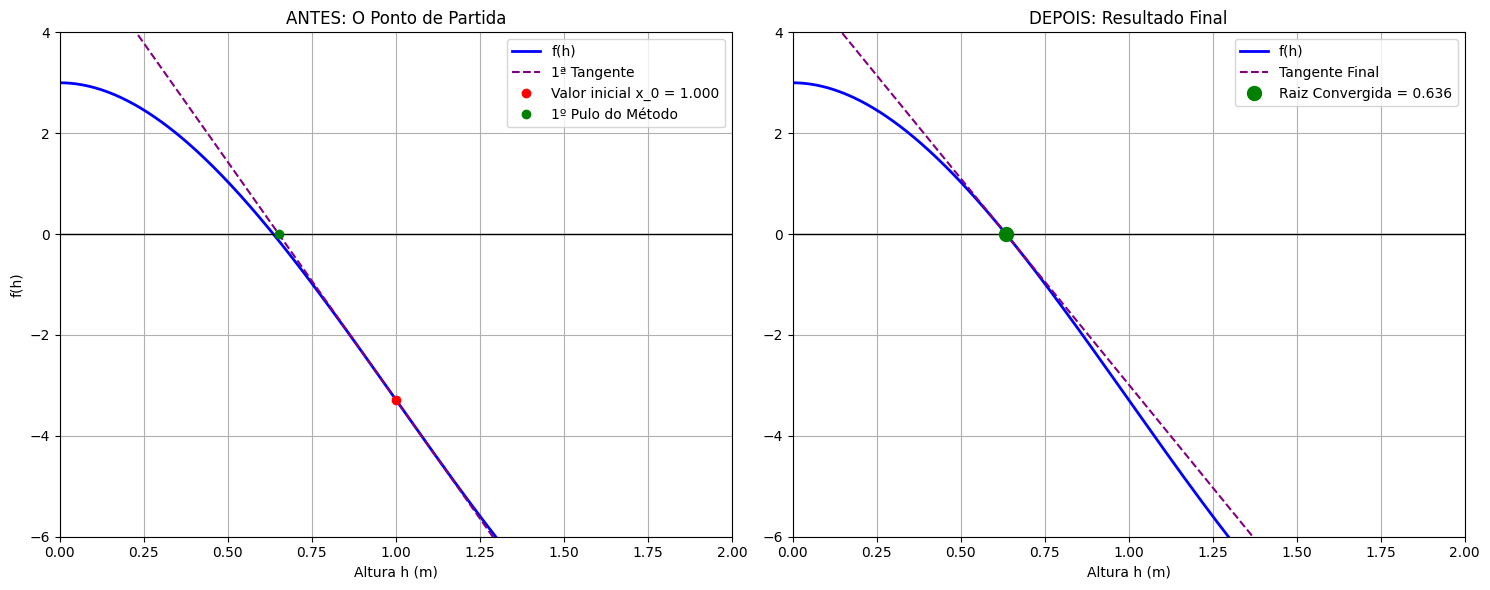

In [ ]:
def plot_comparativo(x_inicial, x_final):
    plt.figure(figsize=(15, 6))

    # --- GRÁFICO 1: ANTES (O valor inicial) ---
    plt.subplot(1, 2, 1)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Reta Tangente no ponto inicial (x=1.0)
    y_tang_inicial = df(x_inicial) * (h_plot - x_inicial) + f(x_inicial)
    x_next_inicial = x_inicial - f(x_inicial) / df(x_inicial)

    plt.plot(h_plot, y_tang_inicial, color="purple", linestyle="--", label="1ª Tangente")
    plt.plot(x_inicial, f(x_inicial), 'ro', label=f"Valor inicial x_0 = {x_inicial:.3f}")
    plt.plot(x_next_inicial, 0, 'go', label="1º Pulo do Método")

    plt.title("ANTES: O Ponto de Partida")
    plt.xlabel("Altura h (m)")
    plt.ylabel("f(h)")
    plt.ylim(-6, 4); plt.xlim(0, 2); plt.grid(True); plt.legend()

    # --- GRÁFICO 2: DEPOIS (Convergência Final) ---
    plt.subplot(1, 2, 2)
    plt.plot(h_plot, y_plot, label="f(h)", color="blue", lw=2)
    plt.axhline(0, color="black", linewidth=1)

    # Reta Tangente no ponto final (Raiz encontrada)
    y_tang_final = df(x_final) * (h_plot - x_final) + f(x_final)

    plt.plot(h_plot, y_tang_final, color="purple", linestyle="--", label="Tangente Final")
    plt.plot(x_final, f(x_final), 'go', markersize=10, label=f"Raiz Convergida = {x_final:.3f}")

    plt.title("DEPOIS: Resultado Final")
    plt.xlabel("Altura h (m)")
    plt.ylim(-6, 4); plt.xlim(0, 2); plt.grid(True); plt.legend()

    plt.tight_layout()
    plt.show()

# Chamada da função passando o valor inicial (1.0) e o resultado do seu loop (raiz_newton)
plot_comparativo(1.0, raiz_newton)

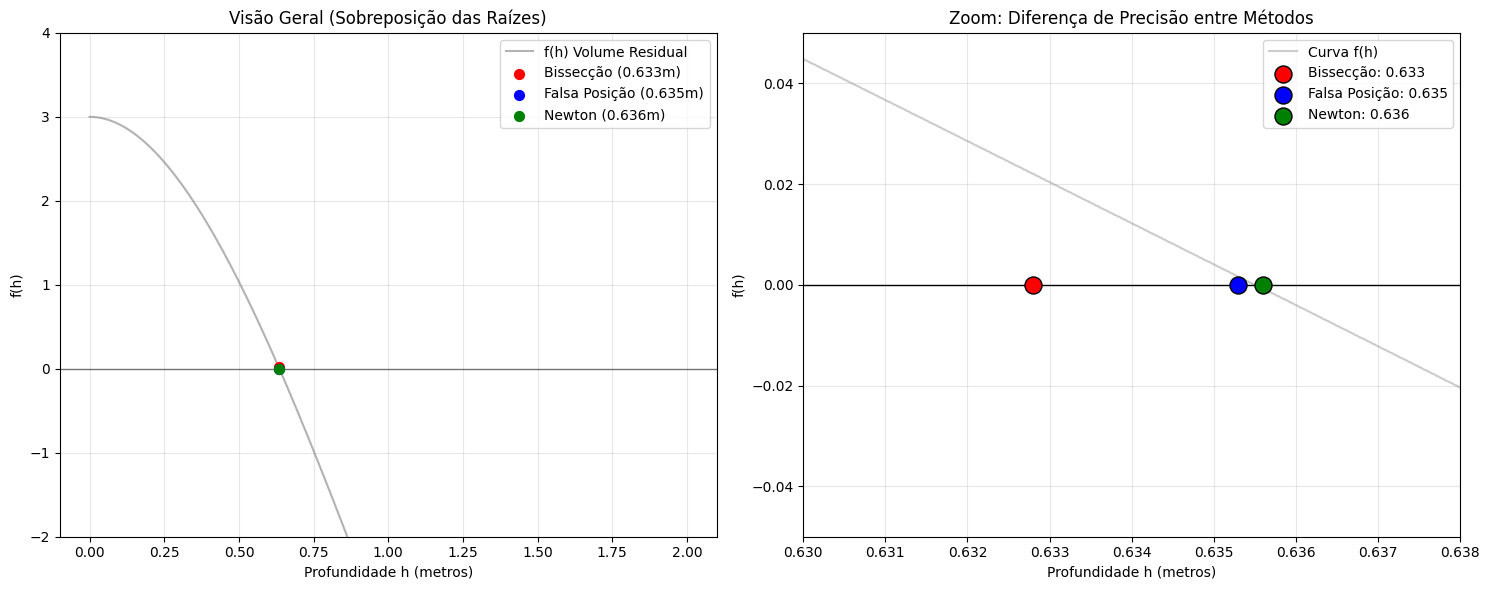

In [ ]:
# Recuperando as raízes
raiz_biss = raiz_biss
raiz_falsa = raiz_falsa
raiz_newton = raiz_newton

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

h_geral = np.linspace(0, 2.0, 500)
y_geral = [f(val) for val in h_geral]

# --- SUBPLOT 1: VISÃO GERAL ---
ax1.plot(h_geral, y_geral, label='f(h) Volume Residual', color='gray', alpha=0.6)
ax1.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)

ax1.scatter(raiz_biss, f(raiz_biss), color='red', s=50, zorder=5, label=f'Bissecção ({raiz_biss:.3f}m)')
ax1.scatter(raiz_falsa, f(raiz_falsa), color='blue', s=50, zorder=5, label=f'Falsa Posição ({raiz_falsa:.3f}m)')
ax1.scatter(raiz_newton, f(raiz_newton), color='green', s=50, zorder=5, label=f'Newton ({raiz_newton:.3f}m)')

ax1.set_title('Visão Geral (Sobreposição das Raízes)')
ax1.set_xlabel('Profundidade h (metros)')
ax1.set_ylabel('f(h)')
ax1.set_ylim(-2, 4)
ax1.grid(True, alpha=0.3)
ax1.legend()


# --- SUBPLOT 2: ZOOM ---
# Centralizando o zoom entre 0.630 e 0.640 para ver as diferenças claramente
h_zoom = np.linspace(0.630, 0.640, 500)
y_zoom = [f(val) for val in h_zoom]

ax2.plot(h_zoom, y_zoom, color='gray', alpha=0.4, label='Curva f(h)')
ax2.axhline(0, color='black', linestyle='-', linewidth=1) # Linha do zero para referência

# Plotamos as raízes em Y=0 para destacar a diferença no eixo X
ax2.scatter(raiz_biss, 0, color='red', s=150, edgecolors='black', zorder=5, label=f'Bissecção: {raiz_biss:.3f}')
ax2.scatter(raiz_falsa, 0, color='blue', s=150, edgecolors='black', zorder=5, label=f'Falsa Posição: {raiz_falsa:.3f}')
ax2.scatter(raiz_newton, 0, color='green', s=150, edgecolors='black', zorder=5, label=f'Newton: {raiz_newton:.3f}')

ax2.set_title('Zoom: Diferença de Precisão entre Métodos')
ax2.set_xlabel('Profundidade h (metros)')
ax2.set_ylabel('f(h)')

# Ajuste fino dos limites para o zoom ficar "confortável"
ax2.set_xlim(0.630, 0.638)
ax2.set_ylim(-0.05, 0.05)

ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()